# Matching LINET flashes with MTG-LI groups — September 2024

For each LINET flash, look for the nearest LI group within a time window ±Δt and a distance Δr.
The share of LINET flashes with a partner is the relative detection efficiency (DE) of LI.

Two comparisons:
- LINET flashes vs LI **uncorrected** (positions as seen by the satellite)
- LINET flashes vs LI **corrected** (after parallax correction)

Uses `data_io.py` and `match_strokes.py` from the same folder.

## 1. Setup

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from data_io import read_strokes_dir, summary, DOMAIN
import match_strokes as ms

plt.rcParams["figure.dpi"] = 110

## 2. Parameters

In [4]:
LINET_DIR = Path("../linet_data")
LI_DIR    = Path("../LI_september/daily")

PATTERN_FLASHES   = "LinetFlashesData*.txt"
PATTERN_LI_UNCORR = "*_uncorrected*.txt"
PATTERN_LI_CORR   = "*_corrected*.txt"   # does not match '_uncorrected'

# Threshold grids for the detection-efficiency sweep
DT_LIST_MS = [50, 100, 150, 200, 300, 500, 700, 1000, 1500, 2000, 3000, 4000]
DR_LIST_KM = [1, 2, 3, 5, 7, 10, 15, 20, 25, 30, 40, 50, 70, 100]

# Reference window for the summary table and diagnostics
DT_REF_MS = 1000
DR_REF_KM = 20

PLOTS_DIR   = Path("plots");   PLOTS_DIR.mkdir(exist_ok=True)
RESULTS_DIR = Path("results"); RESULTS_DIR.mkdir(exist_ok=True)

## 3. Load data

In [5]:
linet_flashes = read_strokes_dir(LINET_DIR, pattern=PATTERN_FLASHES, domain=DOMAIN)
summary(linet_flashes, "LINET flashes")

li_uncorr = read_strokes_dir(LI_DIR, pattern=PATTERN_LI_UNCORR, domain=DOMAIN)
summary(li_uncorr, "LI uncorrected")

li_corr = read_strokes_dir(LI_DIR, pattern=PATTERN_LI_CORR, domain=DOMAIN)
summary(li_corr, "LI corrected")

pairs = {
    "LINET flashes vs LI uncorrected": (linet_flashes, li_uncorr),
    "LINET flashes vs LI corrected":   (linet_flashes, li_corr),
}

  LinetFlashesData20240901.txt:   12565 strokes (in domain)
  LinetFlashesData20240902.txt:   50097 strokes (in domain)
  LinetFlashesData20240903.txt:   74725 strokes (in domain)
  LinetFlashesData20240904.txt:  167515 strokes (in domain)
  LinetFlashesData20240905.txt:  216238 strokes (in domain)
  LinetFlashesData20240906.txt:   13055 strokes (in domain)
  LinetFlashesData20240907.txt:    9909 strokes (in domain)
  LinetFlashesData20240908.txt:   89553 strokes (in domain)
  LinetFlashesData20240909.txt:   35468 strokes (in domain)
  LinetFlashesData20240910.txt:   12204 strokes (in domain)
  LinetFlashesData20240911.txt:    8638 strokes (in domain)
  LinetFlashesData20240912.txt:   43573 strokes (in domain)
  LinetFlashesData20240913.txt:    8109 strokes (in domain)
  LinetFlashesData20240914.txt:    1996 strokes (in domain)
  LinetFlashesData20240915.txt:       6 strokes (in domain)
  LinetFlashesData20240916.txt:    3645 strokes (in domain)
  LinetFlashesData20240917.txt:   44825 

## 4. Matching at a reference window

One run per comparison. The signed median Δt and the median Δlon / Δlat show systematic offsets:
parallax correction should change the spatial shift, but **not** the time offset.

In [6]:
matches = {label: ms.match_nearest(a, b, dt_max_ms=DT_REF_MS, dr_max_km=DR_REF_KM)
           for label, (a, b) in pairs.items()}

table = ms.matching_summary_table(matches)
table.to_csv(RESULTS_DIR / f"summary_dt{DT_REF_MS}ms_dr{DR_REF_KM}km.csv")
table.round(3)

,LINET flashes vs LI uncorrected,LINET flashes vs LI corrected
Total events,998706.000,998706.000
Matched events,667076.000,760692.000
DE (%),66.794,76.168
|dt| median (ms),128.000,66.000
|dt| 90th pct (ms),666.000,613.000
dr median (km),12.244,8.112
dr 90th pct (km),17.926,14.878
dt signed median (ms),125.000,0.000
Δlon median (°),0.074,0.045
Δlat median (°),0.066,-0.004


  saved plots/match_diagnostics_0.png


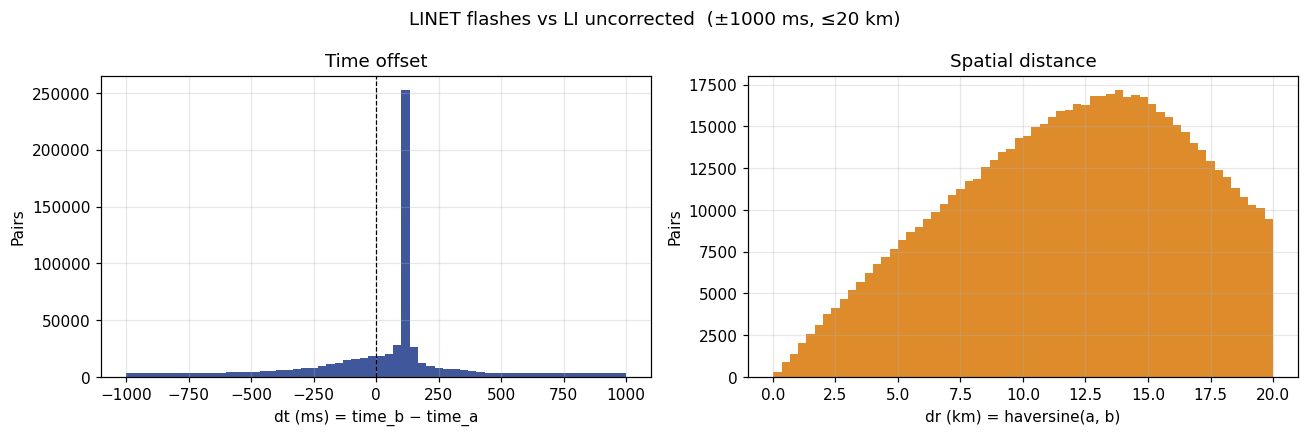

  saved plots/match_diagnostics_1.png


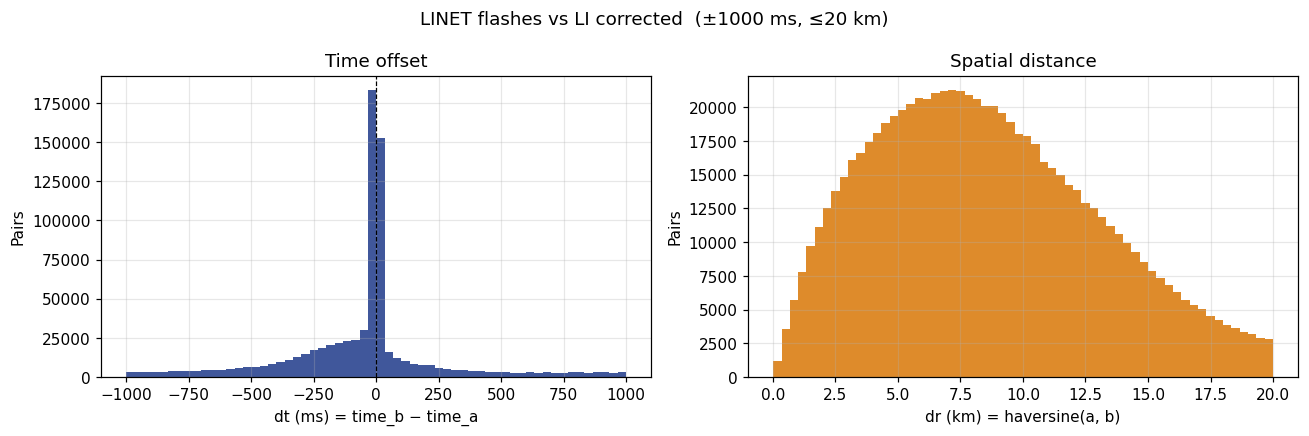

In [7]:
for i, (label, m) in enumerate(matches.items()):
    ms.plot_match_diagnostics(m, outpath=PLOTS_DIR / f"match_diagnostics_{i}.png",
                              title=f"{label}  (±{DT_REF_MS} ms, ≤{DR_REF_KM} km)")

## 5. Detection efficiency vs matching window

The sweep runs `match_nearest` for every (Δt, Δr) pair, which takes a while on a full month.
Results are cached in `results/`, so the figure can be rebuilt without the raw data.

In [8]:
sweeps = {}
for i, (label, (a, b)) in enumerate(pairs.items()):
    cache = RESULTS_DIR / f"sweep_{i}.csv"
    if cache.exists():
        sweep = pd.read_csv(cache, index_col=0)
        sweep.columns = sweep.columns.astype(float).astype(int)
    else:
        print(label)
        sweep = ms.sweep_thresholds(a, b, DT_LIST_MS, DR_LIST_KM, verbose=True)
        sweep.to_csv(cache)
    sweeps[label] = sweep

LINET flashes vs LI uncorrected
  [1/168] dt=50 ms, dr=1 km ... DE=0.000
  [2/168] dt=50 ms, dr=2 km ... DE=0.001
  [3/168] dt=50 ms, dr=3 km ... DE=0.002
  [4/168] dt=50 ms, dr=5 km ... DE=0.004
  [5/168] dt=50 ms, dr=7 km ... DE=0.009
  [6/168] dt=50 ms, dr=10 km ... DE=0.018
  [7/168] dt=50 ms, dr=15 km ... DE=0.043
  [8/168] dt=50 ms, dr=20 km ... DE=0.066
  [9/168] dt=50 ms, dr=25 km ... DE=0.078
  [10/168] dt=50 ms, dr=30 km ... DE=0.083
  [11/168] dt=50 ms, dr=40 km ... DE=0.089
  [12/168] dt=50 ms, dr=50 km ... DE=0.094
  [13/168] dt=50 ms, dr=70 km ... DE=0.102
  [14/168] dt=50 ms, dr=100 km ... DE=0.111
  [15/168] dt=100 ms, dr=1 km ... DE=0.000
  [16/168] dt=100 ms, dr=2 km ... DE=0.001
  [17/168] dt=100 ms, dr=3 km ... DE=0.003
  [18/168] dt=100 ms, dr=5 km ... DE=0.009
  [19/168] dt=100 ms, dr=7 km ... DE=0.018
  [20/168] dt=100 ms, dr=10 km ... DE=0.038
  [21/168] dt=100 ms, dr=15 km ... DE=0.091
  [22/168] dt=100 ms, dr=20 km ... DE=0.140
  [23/168] dt=100 ms, dr=25 km .

  saved plots/detection_curves.png


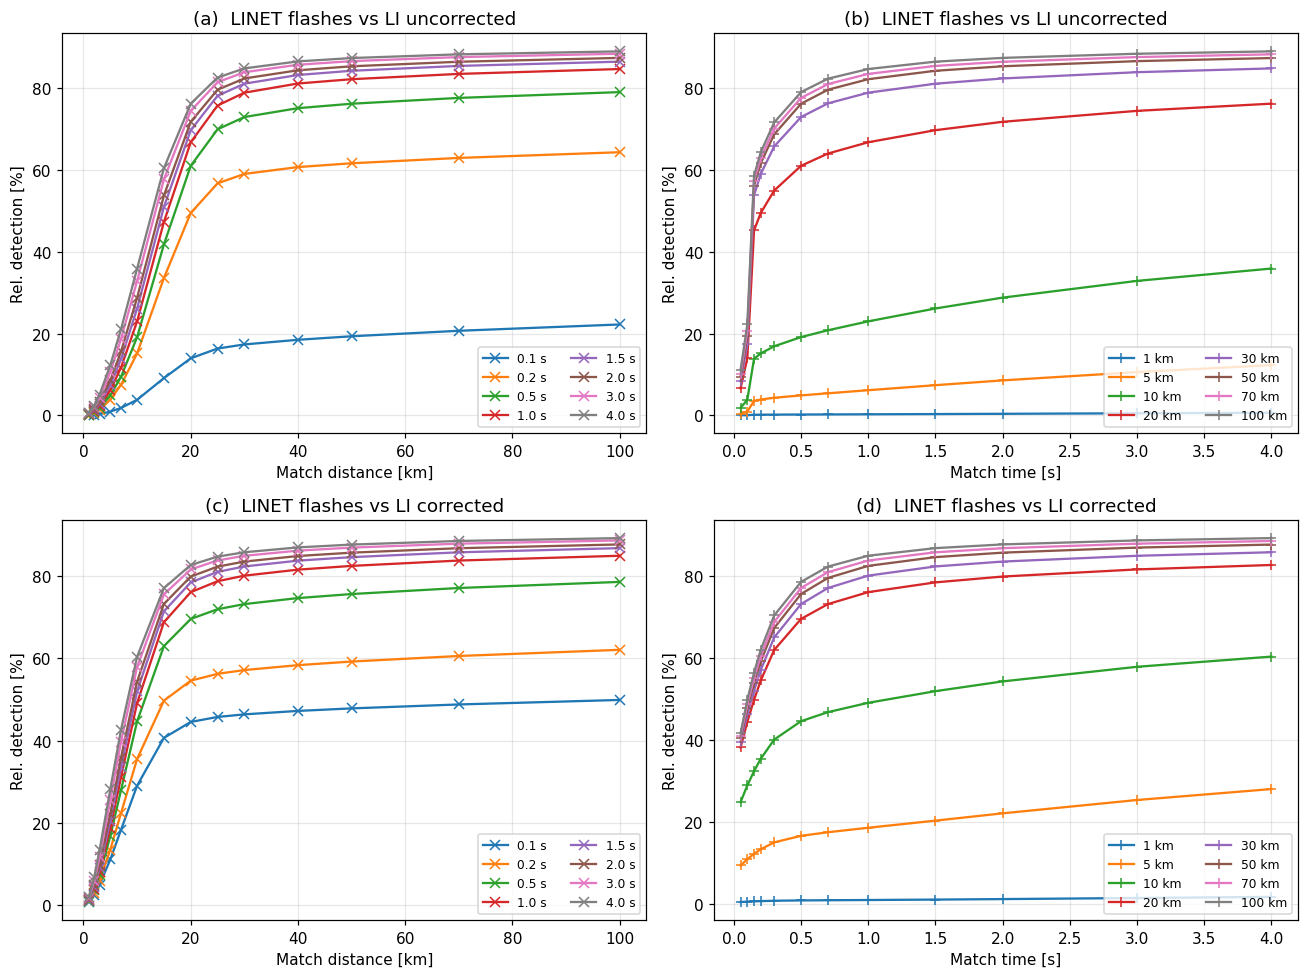

In [10]:
ms.plot_detection_curves(sweeps, outpath=PLOTS_DIR / "detection_curves.png")